<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_5_convgru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 5: ConvGRU (space + time)

**ConvGRU** — like ConvLSTM (space + time) but with a **simpler memory**, so fewer parameters.

**Same for every model** (so the comparison is fair): same inputs (13 ocean variables + usual fishing
grounds), same split (train Mar 2022–Dec 2023, validate 2024, test 2025), same loss, early stopping,
MC dropout and calibration.

**How the forecast is used:** the input days end **yesterday**, and the model predicts
**Day 1 = today, Day 2 = tomorrow, Day 3 = the day after** (72 h). Fishing data is used only as the
**teacher** (training labels), never as an input.

**Method (switches in Step 2):**
* **Residual learning** (`RESIDUAL = True`) – the model starts from the *usual fishing grounds* (climatology)
  and only learns the **corrections** that today's ocean conditions suggest.
* **Pre-training → fine-tuning** (`USE_PRETRAIN = False`, switched off) – the idea was to **pre-train on
  2017–Nov 2021** and then **fine-tune on Mar 2022–Dec 2023**. But GFW coverage before 2022 is much lower
  (0.5% vs 11% fishing cells), and pre-training **lowered** validation PR-AUC (tuning runs without it:
  ConvLSTM 0.593 vs 0.570, ConvGRU 0.592 vs 0.549). So the final models train on Mar 2022–Dec 2023 only.
  Set it to `True` to reproduce the experiment.
* **Usual fishing grounds** for training days are built *leave-one-year-out*, so they never contain the answer.

**How to run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
If Colab disconnects, `Run all` again: training continues where it stopped (each stage saves every epoch).

## Step 1 – Connect Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
BASE = '/content/drive/MyDrive/C2_data'
CKPT_ROOT = f'{BASE}/checkpoints'; os.makedirs(CKPT_ROOT, exist_ok=True)
OUT = f'{BASE}/results';           os.makedirs(OUT, exist_ok=True)
LOCAL_CUBE = '/content/datacube_0p25.nc'
if not os.path.exists(LOCAL_CUBE):                 # copy once to Colab's fast disk (much quicker than reading Drive)
    shutil.copy(f'{BASE}/datacube_0p25.nc', LOCAL_CUBE)
print('Datacube ready:', LOCAL_CUBE)

Mounted at /content/drive
Datacube ready: /content/datacube_0p25.nc


## Step 2 – Settings

In [ ]:
import numpy as np, pandas as pd, xarray as xr, time, json, pickle, copy
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '(turn on the T4 GPU if this says cpu)')
torch.manual_seed(42); np.random.seed(42)

# ---- same for EVERY model (fair comparison) ----
T_IN, LEADS = 7, 3                     # 7 input days (ending yesterday) -> Day 1, Day 2, Day 3
# GFW coverage in this area rose sharply Dec 2021 - early 2022 (0.5% -> 7-14% fishing cells),
# so labels before Mar 2022 are not comparable: they are used ONLY for pre-training (below).
TRAIN    = ('2022-03-01', '2023-12-31')
VAL      = ('2024-01-01', '2024-12-31')
TEST     = ('2025-01-01', '2025-12-31')
PRETRAIN = ('2017-01-01', '2021-11-30')   # old low-coverage years: learn ocean patterns, then fine-tune
FEATURES = ['sst', 'sst_grad', 'log_chl', 'sla', 'u', 'v', 'cur_speed', 'mld',
            'depth', 'moon_sin', 'moon_cos', 'doy_sin', 'doy_cos',
            'fish_clim']               # usual fishing grounds (leave-one-year-out, see Step 3)

# ---- method switches (the comparison notebook reports what was used) ----
RESIDUAL     = True    # model learns CORRECTIONS on top of climatology (usual fishing grounds)
USE_PRETRAIN = False   # pre-train on PRETRAIN years, then fine-tune on TRAIN

EPOCHS, BATCH, LR, DROPOUT = 30, 16, 1e-3, 0.2
PATIENCE = 5                           # early stopping (fine-tuning / normal training)
PRE_EPOCHS, PRE_PATIENCE = 15, 3       # pre-training
FINETUNE_LR = 3e-4                     # smaller learning rate when fine-tuning a pre-trained model
MC_RUNS, CAL_RUNS = 30, 10             # MC dropout runs for test / for fitting calibration

MODEL_NAME, MODEL_LABEL = 'convgru', 'ConvGRU (space + time)'

Device: cuda (turn on the T4 GPU if this says cpu)


## Step 3 – Load the datacube and build the inputs

In [ ]:
X = xr.open_dataset(LOCAL_CUBE).load()
days = pd.DatetimeIndex(X.time.values)
ocean = X['depth'].isel(time=0).notnull().values                   # (H, W) True = sea
label = np.nan_to_num(X['fishing'].values).astype('float32')       # (time, H, W) 1 = fishing
tr  = (days >= TRAIN[0]) & (days <= TRAIN[1])
pre = (days >= PRETRAIN[0]) & (days <= PRETRAIN[1])

# Usual fishing grounds = how often each cell was fished in this month.
#  * validation / test days: full training period
#  * training and pre-training days: LEAVE-ONE-YEAR-OUT (from the other years of the same period),
#    so the map never contains the answer for that day.
clim_m = np.stack([label[tr & (days.month == m)].mean(0) for m in range(1, 13)])     # (12, H, W)
fc = clim_m[np.asarray(days.month) - 1].copy()
def leave_one_year_out(period):
    for y in sorted(set(days[period].year)):
        other = period & (days.year != y)
        if not other.any(): continue
        other_all = label[other].mean(0)                   # fallback: other years, all months
        for m in range(1, 13):
            these = period & (days.year == y) & (days.month == m)
            if not these.any(): continue
            src = other & (days.month == m)
            fc[these] = label[src].mean(0) if src.any() else other_all
leave_one_year_out(tr); leave_one_year_out(pre)
X['fish_clim'] = (('time', 'latitude', 'longitude'), np.where(ocean, fc, np.nan).astype('float32'))

# Residual learning: the climatology of the TARGET day, as a logit offset added to the model output
pc = np.clip(fc, 1e-3, 1 - 1e-3)
OFF = np.where(ocean, np.log(pc / (1 - pc)), 0).astype('float32')

# Features -> (time, channel, H, W), normalised with TRAINING statistics only
feat = np.stack([X[v].values for v in FEATURES], axis=1).astype('float32')
mean = np.nanmean(feat[tr], axis=(0, 2, 3), keepdims=True)
std  = np.nanstd(feat[tr],  axis=(0, 2, 3), keepdims=True) + 1e-6
feat = np.nan_to_num((feat - mean) / std, nan=0.0)                 # land / gaps -> 0

NT, C, H, W = feat.shape
lat, lon = X.latitude.values, X.longitude.values
print(f'{NT} days, {C} input channels, grid {H}x{W}, sea cells {ocean.sum()}')
for nm, (a, b) in [('pretrain', PRETRAIN), ('train', TRAIN), ('val', VAL), ('test', TEST)]:
    sel = (days >= a) & (days <= b)
    print(f'Fishing rate {nm:8s} {a[:7]}..{b[:7]}:', round(float(label[sel][:, ocean].mean()), 4))
json.dump({'features': FEATURES, 'mean': mean.ravel().tolist(), 'std': std.ravel().tolist()},
          open(f'{OUT}/normalisation.json', 'w'))

3287 days, 14 input channels, grid 40x44, sea cells 1421
Fishing rate pretrain 2017-01..2021-11: 0.0045
Fishing rate train    2022-03..2023-12: 0.1127
Fishing rate val      2024-01..2024-12: 0.1387
Fishing rate test     2025-01..2025-12: 0.0725


## Step 4 – Samples and the scoring function

In [ ]:
def sel_ids(period, t_in=T_IN):
    first = np.arange(t_in - 1, NT - LEADS)              # t = last input day ("yesterday")
    tgt = days[first + 1]                                # Day 1 = t + 1 ("today")
    return first[(tgt >= period[0]) & (tgt <= period[1])]
idx_pre, idx_tr, idx_va, idx_te = sel_ids(PRETRAIN), sel_ids(TRAIN), sel_ids(VAL), sel_ids(TEST)
print('samples  pretrain', len(idx_pre), ' train', len(idx_tr), ' val', len(idx_va), ' test', len(idx_te))

FEAT_T, LAB_T, OFF_T = torch.from_numpy(feat), torch.from_numpy(label), torch.from_numpy(OFF)
class Windows(torch.utils.data.Dataset):
    def __init__(self, ids, t_in=T_IN): self.ids, self.t_in = ids, t_in
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        t = self.ids[i]
        return (FEAT_T[t - self.t_in + 1: t + 1], LAB_T[t + 1: t + 1 + LEADS],
                OFF_T[t + 1: t + 1 + LEADS], t)
def loader(ids, t_in=T_IN, shuffle=False):
    return torch.utils.data.DataLoader(Windows(ids, t_in), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle)

def scores(prob, ids):
    # prob: (n, LEADS, H, W). Scores sea cells only. PR-AUC is the main score (fishing cells are rare).
    rows = []
    for k in range(LEADS):
        y = label[ids + 1 + k][:, ocean].ravel()
        p = np.clip(prob[:, k][:, ocean].ravel(), 1e-6, 1 - 1e-6)
        rows.append({'lead_day': k + 1, 'PR_AUC': average_precision_score(y, p),
                     'ROC_AUC': roc_auc_score(y, p), 'Brier': brier_score_loss(y, p)})
    return pd.DataFrame(rows).round(4)

samples  pretrain 1788  train 671  val 366  test 363


## Step 5 – The model: ConvGRU (space + time)

In [ ]:
class ConvGRUCell(nn.Module):
    def __init__(self, cin, ch, k=3):
        super().__init__(); self.ch = ch
        self.gates = nn.Conv2d(cin + ch, 2 * ch, k, padding=k // 2)   # update (z) and reset (r) gates
        self.cand  = nn.Conv2d(cin + ch, ch, k, padding=k // 2)
    def forward(self, x, h):
        z, r = torch.chunk(torch.sigmoid(self.gates(torch.cat([x, h], 1))), 2, 1)
        n = torch.tanh(self.cand(torch.cat([x, r * h], 1)))
        return (1 - z) * h + z * n

class ConvGRUNet(nn.Module):
    # Space + time, like ConvLSTM but a simpler memory (no separate cell state) -> fewer parameters
    def __init__(self, cin, p=0.2, out=3, hidden=(32, 32)):
        super().__init__()
        self.cells = nn.ModuleList(); prev = cin
        for ch in hidden:
            self.cells.append(ConvGRUCell(prev, ch)); prev = ch
        self.drop = nn.Dropout2d(p)
        self.head = nn.Sequential(nn.Conv2d(prev, 32, 3, padding=1), nn.ReLU(),
                                  nn.Dropout2d(p), nn.Conv2d(32, out, 1))
    def forward(self, x):                                  # x: (B, T, C, H, W)
        B, T, _, H, W = x.shape
        state = [x.new_zeros(B, c.ch, H, W) for c in self.cells]
        for t in range(T):
            inp = x[:, t]
            for j, cell in enumerate(self.cells):
                state[j] = cell(inp, state[j])
                inp = self.drop(state[j]) if j < len(self.cells) - 1 else state[j]
        return self.head(self.drop(inp))

MODEL_ARGS = dict(hidden=[32, 32])
def build_model(p=DROPOUT, args=None):
    return ConvGRUNet(C, p=p, out=LEADS, **(MODEL_ARGS if args is None else args))

## Step 6 – Training functions
Loss = binary cross-entropy on sea cells only, with extra weight on the rare fishing cells.
Each stage uses early stopping on the **validation (2024) PR-AUC** and saves a checkpoint every epoch.

In [ ]:
CKPT = f'{CKPT_ROOT}/{MODEL_NAME}'; os.makedirs(CKPT, exist_ok=True)
mask_dev = torch.from_numpy(ocean.astype('float32')).to(DEVICE)

def pos_weight_for(period_mask):                     # extra weight for the rare fishing cells
    p = label[period_mask][:, ocean].mean()
    return torch.tensor(min((1 - p) / max(p, 1e-4), 50.0)).to(DEVICE)
PW_PRE, PW = pos_weight_for(pre), pos_weight_for(tr)
LOG_W = torch.log(PW)                                # removes the class weighting at prediction time

def masked_loss(logits, y, pw):
    l = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pw, reduction='none')
    m = mask_dev.expand_as(l)
    return (l * m).sum() / m.sum()

def logits_of(m, xb, ob):
    out = m(xb)
    return out + ob if RESIDUAL else out             # residual: climatology + learned correction

def zero_last_layer(m):
    # residual start: the untrained model outputs 0 correction = pure climatology
    last = [l for l in m.modules() if isinstance(l, nn.Conv2d)][-1]
    nn.init.zeros_(last.weight); nn.init.zeros_(last.bias)

def enable_mc(m):
    # MC dropout: dropout ON, everything else (e.g. BatchNorm) in normal prediction mode
    m.eval()
    for layer in m.modules():
        if isinstance(layer, (nn.Dropout, nn.Dropout2d)): layer.train()

@torch.no_grad()
def predict(m, dl, runs=1, calib=None):
    enable_mc(m) if runs > 1 else m.eval()
    means, stds, ids = [], [], []
    for xb, _, ob, tb in dl:
        xb, ob = xb.to(DEVICE), ob.to(DEVICE)
        ps = torch.stack([torch.sigmoid(logits_of(m, xb, ob) - LOG_W) for _ in range(runs)]).cpu().numpy()
        if calib is not None:
            for k in range(LEADS):
                ps[:, :, k] = calib[k].predict(ps[:, :, k].ravel()).reshape(ps[:, :, k].shape)
        means.append(ps.mean(0)); stds.append(ps.std(0)); ids.append(tb.numpy())
    return np.concatenate(means), np.concatenate(stds), np.concatenate(ids)

def train_stage(m, dl_train, dl_val, pw, lr, epochs, patience, tag=None, config=None, verbose=True):
    """Train with early stopping on validation PR-AUC. tag = checkpoint name (resumable), None = no files."""
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    start, best, best_ep, hist, best_state = 1, -1.0, 0, [], None
    last_f, best_f = (f'{CKPT}/{tag}_last.pt', f'{CKPT}/{tag}_best.pt') if tag else (None, None)
    if tag and os.path.exists(last_f):
        ck = torch.load(last_f, map_location=DEVICE, weights_only=False)
        if ck.get('config') == config:
            if ck.get('done'):
                m.load_state_dict(torch.load(best_f, map_location=DEVICE))
                if verbose: print(f'[{tag}] already finished (best val PR-AUC {ck["best"]:.4f}) -> loaded')
                return ck['best'], ck['best_ep'], ck['history']
            m.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            start, best, best_ep, hist = ck['epoch'] + 1, ck['best'], ck['best_ep'], ck['history']
            if verbose: print(f'[{tag}] resuming from epoch {start}')
        elif verbose: print(f'[{tag}] settings changed -> starting again')
    for ep in range(start, epochs + 1):
        if best_ep and ep - best_ep > patience:
            if verbose: print(f'[{tag or "trial"}] early stop (best = epoch {best_ep})')
            break
        m.train(); t0 = time.time(); tot = 0
        for xb, yb, ob, _ in dl_train:
            xb, yb, ob = xb.to(DEVICE), yb.to(DEVICE), ob.to(DEVICE)
            loss = masked_loss(logits_of(m, xb, ob), yb, pw)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
            tot += loss.item()
        sched.step()
        pv, _, iv = predict(m, dl_val); pr = float(scores(pv, iv).PR_AUC.mean())
        hist.append({'epoch': ep, 'train_loss': tot / len(dl_train), 'val_PR_AUC': pr})
        improved = pr > best
        if improved:
            best, best_ep = pr, ep
            if tag: torch.save(m.state_dict(), best_f)
            else: best_state = copy.deepcopy(m.state_dict())
        if tag:
            torch.save({'model': m.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(), 'epoch': ep,
                        'best': best, 'best_ep': best_ep, 'history': hist, 'config': config}, last_f)
        if verbose:
            print(f'[{tag or "trial"}] epoch {ep:2d}/{epochs}  loss {tot/len(dl_train):.4f}  '
                  f'val PR-AUC {pr:.4f}  ({time.time()-t0:.0f}s){"  *best*" if improved else ""}')
    if tag:
        m.load_state_dict(torch.load(best_f, map_location=DEVICE))
        ck = torch.load(last_f, map_location=DEVICE, weights_only=False); ck['done'] = True; torch.save(ck, last_f)
    elif best_state is not None:
        m.load_state_dict(best_state)
    return best, best_ep, hist

def run_pipeline(t_in=T_IN, dropout=DROPOUT, lr=LR, model_args=None, pretrain=USE_PRETRAIN,
                 seed=42, save=False, verbose=True):
    """(optional) pre-train on PRETRAIN -> fine-tune / train on TRAIN, early stopping on VAL."""
    torch.manual_seed(seed); np.random.seed(seed)
    args = MODEL_ARGS if model_args is None else model_args
    m = build_model(dropout, args).to(DEVICE)
    if RESIDUAL: zero_last_layer(m)
    cfg = dict(model=MODEL_NAME, model_args=args, features=FEATURES, T_IN=t_in, LEADS=LEADS, BATCH=BATCH,
               LR=lr, DROPOUT=dropout, TRAIN=TRAIN, VAL=VAL, TEST=TEST, RESIDUAL=RESIDUAL,
               PRETRAIN=PRETRAIN if pretrain else None, FINETUNE_LR=FINETUNE_LR, seed=seed, fish_clim='loyo')
    dl_val = loader(sel_ids(VAL, t_in), t_in)
    hist = []
    if pretrain:
        _, _, h = train_stage(m, loader(sel_ids(PRETRAIN, t_in), t_in, True), dl_val, PW_PRE, lr,
                              PRE_EPOCHS, PRE_PATIENCE, 'pretrain' if save else None, cfg, verbose)
        hist += [dict(r, stage='pre-train') for r in h]
    best, best_ep, h = train_stage(m, loader(sel_ids(TRAIN, t_in), t_in, True), dl_val, PW,
                                   FINETUNE_LR if pretrain else lr, EPOCHS, PATIENCE,
                                   ('finetune' if pretrain else 'train') if save else None, cfg, verbose)
    hist += [dict(r, stage='fine-tune' if pretrain else 'train') for r in h]
    return m, best, best_ep, hist, cfg

## Step 7 – Train

[pretrain] already finished (best val PR-AUC 0.4570) -> loaded
[finetune] already finished (best val PR-AUC 0.5561) -> loaded

convgru: 104,579 parameters | best val PR-AUC 0.5561 | residual=True | pre-training=True


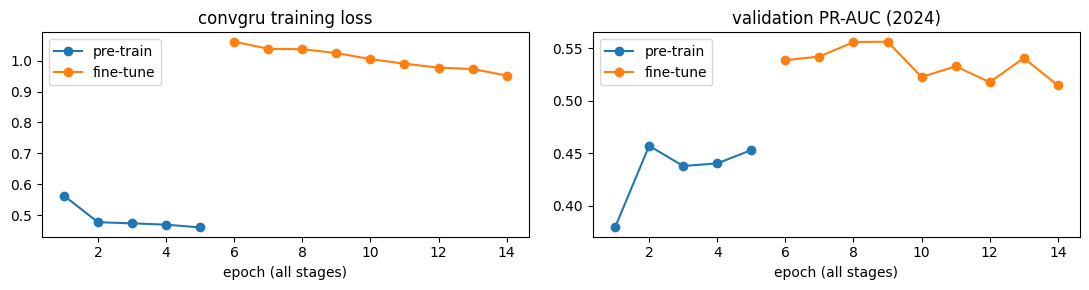

In [ ]:
model, best_val, best_ep, history, CONFIG = run_pipeline(save=True)
torch.save(model.state_dict(), f'{CKPT}/best.pt')
json.dump(CONFIG, open(f'{OUT}/{MODEL_NAME}_config.json', 'w'))
print(f'\n{MODEL_NAME}: {sum(p.numel() for p in model.parameters()):,} parameters | '
      f'best val PR-AUC {best_val:.4f} | residual={RESIDUAL} | pre-training={USE_PRETRAIN}')

h = pd.DataFrame(history); h['step'] = range(1, len(h) + 1)
h.to_csv(f'{OUT}/{MODEL_NAME}_history.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for st, g in h.groupby('stage', sort=False):
    ax[0].plot(g.step, g.train_loss, 'o-', label=st); ax[1].plot(g.step, g.val_PR_AUC, 'o-', label=st)
ax[0].set_title(f'{MODEL_NAME} training loss'); ax[1].set_title('validation PR-AUC (2024)')
for a in ax: a.set_xlabel('epoch (all stages)'); a.legend()
plt.tight_layout(); plt.show()

## Step 8 – Calibrate on 2024, then test on 2025 with MC dropout
**Calibration** maps raw outputs to real probabilities (fitted on 2024 only).
**MC dropout**: 30 runs with dropout ON → mean = probability, spread = uncertainty.
Note: GFW recorded about half as much fishing in 2025 as in 2024, so 2025 probabilities will be somewhat
too high; ranking scores (PR-AUC, ROC-AUC) are not affected.

In [ ]:
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=DEVICE))
dl_va, dl_te = loader(idx_va), loader(idx_te)

# 1) Calibration, fitted on the 2024 validation year only (never on the test year)
pv, _, iv = predict(model, dl_va, runs=CAL_RUNS)
calib = [IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1)
         .fit(pv[:, k][:, ocean].ravel(), label[iv + 1 + k][:, ocean].ravel()) for k in range(LEADS)]
pickle.dump(calib, open(f'{OUT}/{MODEL_NAME}_calibrator.pkl', 'wb'))
pv_cal = np.stack([calib[k].predict(pv[:, k].ravel()).reshape(pv[:, k].shape) for k in range(LEADS)], 1)
val_df = scores(pv_cal, iv); val_df.insert(0, 'model', MODEL_LABEL)
val_df.to_csv(f'{OUT}/{MODEL_NAME}_val_scores.csv', index=False)
np.savez_compressed(f'{OUT}/{MODEL_NAME}_val_predictions.npz', mean=pv_cal.astype('float16'), ids=iv)

# 2) Test 2025: MC dropout (probability + uncertainty), calibrated
p_mean, p_std, ids_te = predict(model, dl_te, runs=MC_RUNS, calib=calib)
test_df = scores(p_mean, ids_te); test_df.insert(0, 'model', MODEL_LABEL)
test_df.to_csv(f'{OUT}/{MODEL_NAME}_test_scores.csv', index=False)
np.savez_compressed(f'{OUT}/{MODEL_NAME}_test_predictions.npz', mean=p_mean.astype('float16'),
                    std=p_std.astype('float16'), ids=ids_te)

print('VALIDATION 2024 (used to choose the best model)'); print(val_df.to_string(index=False))
print('\nTEST 2025 (final result for the report)');      print(test_df.to_string(index=False))
print('\nAverage predicted probability:', round(float(p_mean[:, 0][:, ocean].mean()), 3),
      '| real fishing rate:', round(float(label[ids_te + 1][:, ocean].mean()), 3))

VALIDATION 2024 (used to choose the best model)
                 model  lead_day  PR_AUC  ROC_AUC  Brier
ConvGRU (space + time)         1  0.5503   0.8458 0.0864
ConvGRU (space + time)         2  0.5486   0.8450 0.0864
ConvGRU (space + time)         3  0.5491   0.8450 0.0863

TEST 2025 (final result for the report)
                 model  lead_day  PR_AUC  ROC_AUC  Brier
ConvGRU (space + time)         1  0.3829   0.8413 0.0628
ConvGRU (space + time)         2  0.3830   0.8413 0.0627
ConvGRU (space + time)         3  0.3844   0.8412 0.0627

Average predicted probability: 0.136 | real fishing rate: 0.072


## Step 9 – Reliability check and example maps

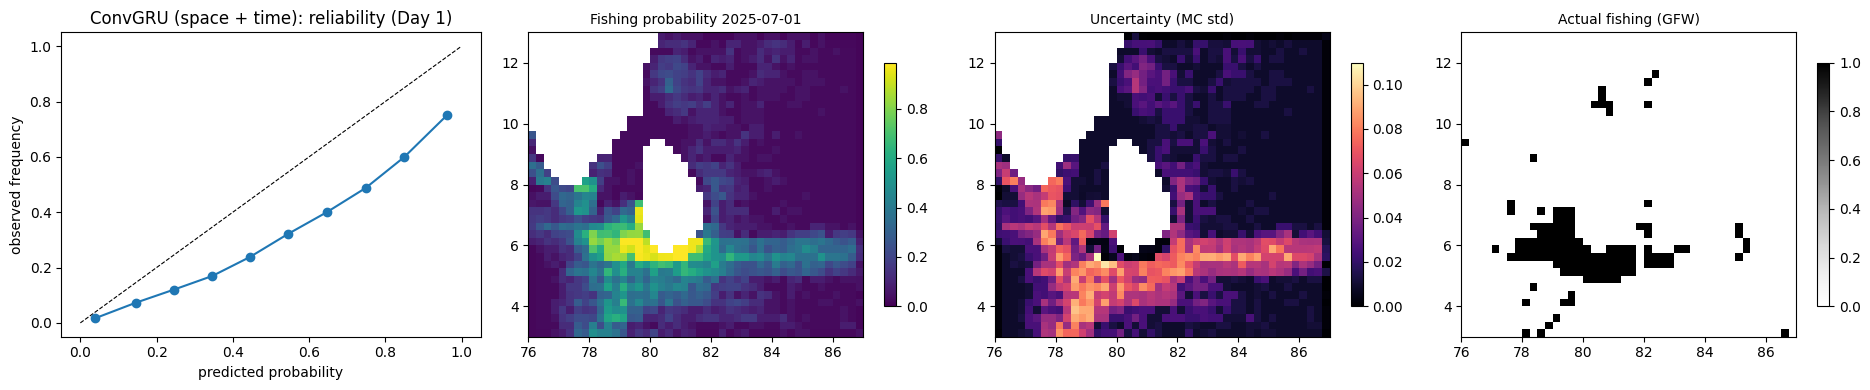

In [ ]:
y = label[ids_te + 1][:, ocean].ravel(); p = p_mean[:, 0][:, ocean].ravel()
b = np.digitize(p, np.linspace(0, 1, 11)) - 1
rel = pd.DataFrame({'b': b, 'p': p, 'y': y}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'))

d = len(ids_te) // 2                                     # a mid-test day
def show(ax, a, title, cmap, vmin=None, vmax=None):
    im = ax.pcolormesh(lon, lat, np.where(ocean, a, np.nan), cmap=cmap, shading='auto', vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.set_aspect('equal'); plt.colorbar(im, ax=ax, shrink=0.8)

fig, ax = plt.subplots(1, 4, figsize=(19, 4))
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].plot(rel.pred, rel.obs, 'o-')
ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed frequency')
ax[0].set_title(f'{MODEL_LABEL}: reliability (Day 1)')
when = days[ids_te[d] + 1].date()
show(ax[1], p_mean[d, 0], f'Fishing probability {when}', 'viridis', 0)
show(ax[2], p_std[d, 0], 'Uncertainty (MC std)', 'magma', 0)
show(ax[3], label[ids_te[d] + 1], 'Actual fishing (GFW)', 'Greys', 0, 1)
plt.tight_layout(); plt.savefig(f'{OUT}/{MODEL_NAME}_example_maps.png', dpi=120); plt.show()

## Step 10 – Seed check (optional, recommended for the report)
Trains the full pipeline 3 more times with different random seeds and reports mean ± std.
The comparison notebook shows this automatically if the file exists.

In [ ]:
# ===== Seed check of the FINAL pipeline: train 3 times with different random seeds =====
# Shows how stable the result is (mean +- std). Uses the current settings (Step 2).
# Scores here are uncalibrated ranking scores (PR-AUC / ROC-AUC are not changed by calibration).
SEED_CSV = f'{OUT}/{MODEL_NAME}_seeds.csv'
done = pd.read_csv(SEED_CSV) if os.path.exists(SEED_CSV) else pd.DataFrame(columns=['seed'])
if len(done) and ('pretrain' not in done or (done.pretrain != USE_PRETRAIN).any()):
    print('saved seed results used other settings -> starting again')
    done = pd.DataFrame(columns=['seed'])
rows = done.to_dict('records')
for seed in [1, 2, 3]:
    if seed in set(done.seed): print('skip seed', seed); continue
    m, best, ep, _, _ = run_pipeline(seed=seed, verbose=False)
    pt, _, it = predict(m, loader(idx_te))
    s = scores(pt, it)
    rows.append({'seed': seed, 'pretrain': USE_PRETRAIN, 'val_PR_AUC': round(best, 4), 'test_PR_AUC': round(float(s.PR_AUC.mean()), 4),
                 'test_ROC_AUC': round(float(s.ROC_AUC.mean()), 4)})
    pd.DataFrame(rows).to_csv(SEED_CSV, index=False)
    print(f'seed {seed}: val PR-AUC {best:.4f} | test PR-AUC {rows[-1]["test_PR_AUC"]:.4f}')
sd = pd.DataFrame(rows)
print('\n', sd.to_string(index=False))
print('\nmean +- std:', {c: f'{sd[c].mean():.4f} +- {sd[c].std():.4f}' for c in ['val_PR_AUC', 'test_PR_AUC', 'test_ROC_AUC']})

skip seed 1
skip seed 2
seed 3: val PR-AUC 0.5701 | test PR-AUC 0.3838

  seed  val_PR_AUC  test_PR_AUC  test_ROC_AUC
    1      0.5479       0.3459        0.8399
    2      0.5532       0.3812        0.8450
    3      0.5701       0.3838        0.8484

mean +- std: {'val_PR_AUC': '0.5571 +- 0.0116', 'test_PR_AUC': '0.3703 +- 0.0212', 'test_ROC_AUC': '0.8444 +- 0.0043'}


## Step 11 – Hyperparameter tuning (optional – do it for the model chosen in Notebook 6)
Run the three cells **in order**. Choose by validation only; the test year is never used.

In [ ]:
TRIALS = [
    dict(name='base',                T_IN=7,  DROPOUT=0.2, LR=1e-3, args={}),
    dict(name='dropout 0.3',         T_IN=7,  DROPOUT=0.3, LR=1e-3, args={}),
    dict(name='dropout 0.4',         T_IN=7,  DROPOUT=0.4, LR=1e-3, args={}),
    dict(name='learning rate 3e-4',  T_IN=7,  DROPOUT=0.2, LR=3e-4, args={}),
    dict(name='smaller (16,16)',     T_IN=7,  DROPOUT=0.2, LR=1e-3, args={'hidden': [16, 16]}),
    dict(name='bigger (64,64)',      T_IN=7,  DROPOUT=0.2, LR=1e-3, args={'hidden': [64, 64]}),
    dict(name='deeper (32,32,32)',   T_IN=7,  DROPOUT=0.2, LR=1e-3, args={'hidden': [32, 32, 32]}),
    dict(name='3 input days',        T_IN=3,  DROPOUT=0.2, LR=1e-3, args={}),
    dict(name='14 input days',       T_IN=14, DROPOUT=0.2, LR=1e-3, args={}),
]

# ===== TUNING: try settings, choose by VALIDATION 2024 PR-AUC only (test year never used) =====
# For speed, trials skip pre-training (TUNE_WITH_PRETRAIN = False); the best setting is then
# used in the full pipeline. Results are saved after every trial: if Colab disconnects, run again.
TUNE_WITH_PRETRAIN = False
TUNE_EPOCHS, TUNE_PATIENCE = 20, 4
TUNE_CSV = f'{OUT}/{MODEL_NAME}_tuning_{VAL[0][:4]}.csv'

def run_trial(cfg, seed=42):
    global EPOCHS, PATIENCE
    keep = (EPOCHS, PATIENCE); EPOCHS, PATIENCE = TUNE_EPOCHS, TUNE_PATIENCE
    try:
        t0 = time.time()
        m, best, ep, _, _ = run_pipeline(t_in=cfg['T_IN'], dropout=cfg['DROPOUT'], lr=cfg['LR'],
                                         model_args={**MODEL_ARGS, **cfg['args']},
                                         pretrain=TUNE_WITH_PRETRAIN, seed=seed, verbose=False)
        return best, ep, (time.time() - t0) / 60, sum(p.numel() for p in m.parameters())
    finally:
        EPOCHS, PATIENCE = keep

tune = pd.read_csv(TUNE_CSV) if os.path.exists(TUNE_CSV) else pd.DataFrame()
for cfg in TRIALS:
    if len(tune) and cfg['name'] in set(tune['name']):
        print('skip (already done):', cfg['name']); continue
    print('running:', cfg['name'], '...', end=' ', flush=True)
    pr, ep, mins, npar = run_trial(cfg)
    row = {'name': cfg['name'], 'T_IN': cfg['T_IN'], 'DROPOUT': cfg['DROPOUT'], 'LR': cfg['LR'],
           'args': json.dumps({**MODEL_ARGS, **cfg['args']}), 'val_PR_AUC': round(pr, 4),
           'best_epoch': ep, 'params': npar, 'minutes': round(mins, 1)}
    tune = pd.concat([tune, pd.DataFrame([row])], ignore_index=True); tune.to_csv(TUNE_CSV, index=False)
    print(f'val PR-AUC {pr:.4f}  (best epoch {ep}, {mins:.1f} min)')
print('\nAll trials done. Saved:', TUNE_CSV)

running: base ... val PR-AUC 0.5932  (best epoch 2, 0.4 min)
running: dropout 0.3 ... val PR-AUC 0.5932  (best epoch 2, 0.4 min)
running: dropout 0.4 ... val PR-AUC 0.5931  (best epoch 2, 0.4 min)
running: learning rate 3e-4 ... val PR-AUC 0.5929  (best epoch 3, 0.5 min)
running: smaller (16,16) ... val PR-AUC 0.5930  (best epoch 2, 0.3 min)
running: bigger (64,64) ... val PR-AUC 0.5860  (best epoch 1, 0.7 min)
running: deeper (32,32,32) ... val PR-AUC 0.5930  (best epoch 1, 0.5 min)
running: 3 input days ... val PR-AUC 0.5934  (best epoch 1, 0.2 min)
running: 14 input days ... val PR-AUC 0.5929  (best epoch 1, 0.6 min)

All trials done. Saved: /content/drive/MyDrive/C2_data/results/convgru_tuning_2024.csv


              name  T_IN  DROPOUT     LR                     args  val_PR_AUC  vs base  best_epoch  params
      3 input days     3      0.2 0.0010     {"hidden": [32, 32]}      0.5934   0.0002           1  104579
              base     7      0.2 0.0010     {"hidden": [32, 32]}      0.5932   0.0000           2  104579
       dropout 0.3     7      0.3 0.0010     {"hidden": [32, 32]}      0.5932   0.0000           2  104579
       dropout 0.4     7      0.4 0.0010     {"hidden": [32, 32]}      0.5931  -0.0001           2  104579
   smaller (16,16)     7      0.2 0.0010     {"hidden": [16, 16]}      0.5930  -0.0002           2   31619
 deeper (32,32,32)     7      0.2 0.0010 {"hidden": [32, 32, 32]}      0.5930  -0.0002           1  159971
learning rate 3e-4     7      0.2 0.0003     {"hidden": [32, 32]}      0.5929  -0.0003           3  104579
     14 input days    14      0.2 0.0010     {"hidden": [32, 32]}      0.5929  -0.0003           1  104579
    bigger (64,64)     7      0.2 0.0

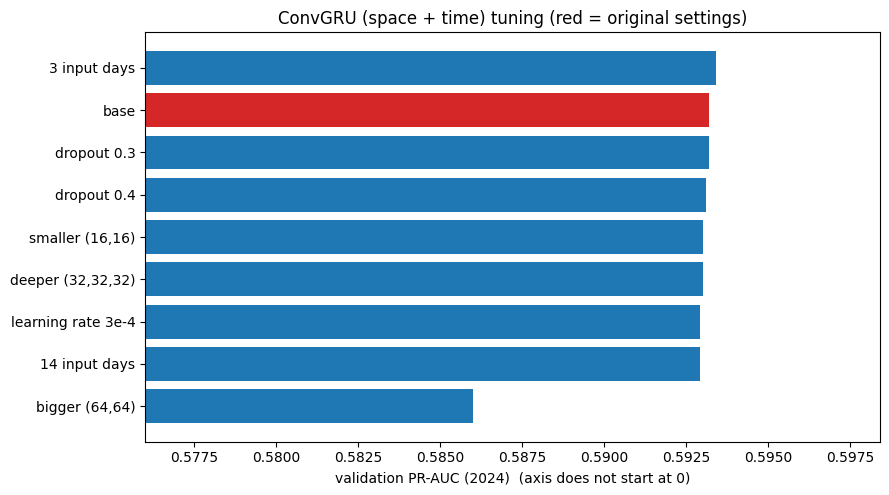


BEST: 3 input days  (val PR-AUC 0.5934, +0.0002 vs base)
Check it with the seed cell below. If confirmed, set these, then click inside the first
tuning cell and use  Runtime -> Run before  (retrains the final model):
  Step 2:  T_IN, LEADS = 3, 3
           EPOCHS, BATCH, LR, DROPOUT = 30, 16, 0.001, 0.2
  Step 5:  MODEL_ARGS = dict(**{"hidden": [32, 32]})


In [ ]:
# ===== Tuning results: best settings by validation PR-AUC =====
tune = pd.read_csv(TUNE_CSV).sort_values('val_PR_AUC', ascending=False).reset_index(drop=True)
base = tune.loc[tune.name == 'base', 'val_PR_AUC'].iloc[0]
tune['vs base'] = (tune.val_PR_AUC - base).round(4)
print(tune[['name', 'T_IN', 'DROPOUT', 'LR', 'args', 'val_PR_AUC', 'vs base', 'best_epoch', 'params']].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(tune) + 1))
ax.barh(tune.name[::-1], tune.val_PR_AUC[::-1], color=['tab:red' if n == 'base' else 'tab:blue' for n in tune.name[::-1]])
ax.set_xlim(tune.val_PR_AUC.min() - 0.01, tune.val_PR_AUC.max() + 0.005)
ax.set_xlabel('validation PR-AUC (2024)  (axis does not start at 0)')
ax.set_title(f'{MODEL_LABEL} tuning (red = original settings)')
plt.tight_layout(); plt.savefig(TUNE_CSV.replace('.csv', '.png'), dpi=130); plt.show()

b = tune.iloc[0]
print(f"\nBEST: {b['name']}  (val PR-AUC {b.val_PR_AUC:.4f}, {b['vs base']:+.4f} vs base)")
print('Check it with the seed cell below. If confirmed, set these, then click inside the first')
print('tuning cell and use  Runtime -> Run before  (retrains the final model):')
print(f"  Step 2:  T_IN, LEADS = {int(b.T_IN)}, 3")
print(f"           EPOCHS, BATCH, LR, DROPOUT = 30, 16, {b.LR:g}, {b.DROPOUT:g}")
print(f"  Step 5:  MODEL_ARGS = dict(**{b.args})")

In [ ]:
# ===== Is the improvement real? Repeat best and base with 3 different seeds =====
tune = pd.read_csv(TUNE_CSV).sort_values('val_PR_AUC', ascending=False).reset_index(drop=True)
best_cfg = next(c for c in TRIALS if c['name'] == tune.iloc[0]['name'])
base_cfg = next(c for c in TRIALS if c['name'] == 'base')
rows = []
for cfg in ([base_cfg, best_cfg] if best_cfg is not base_cfg else [base_cfg]):
    for seed in [1, 2, 3]:
        pr, ep, mins, _ = run_trial(cfg, seed=seed)
        rows.append({'name': cfg['name'], 'seed': seed, 'val_PR_AUC': round(pr, 4)})
        print(cfg['name'], 'seed', seed, f'-> {pr:.4f}')
seeds = pd.DataFrame(rows)
print('\n', seeds.groupby('name').val_PR_AUC.agg(['mean', 'std']).round(4).to_string())
print('If the best setting\'s mean is above base by more than about one std, the gain is real.')
seeds.to_csv(TUNE_CSV.replace('.csv', '_seeds.csv'), index=False)

base seed 1 -> 0.5919
base seed 2 -> 0.5921
base seed 3 -> 0.5926
3 input days seed 1 -> 0.5905
3 input days seed 2 -> 0.5926
3 input days seed 3 -> 0.5923

                 mean     std
name                        
3 input days  0.5918  0.0011
base          0.5922  0.0004
If the best setting's mean is above base by more than about one std, the gain is real.
